In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_o = pd.read_csv('orders_clean.csv')
df_pr = pd.read_csv('products_clean.csv')

In [3]:
df_o.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5.0
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6.0
2,O027337,C03849,2024-12-31,P0072,S0056,1,153.74,0,153.74,115.91,37.83,Cancelled,6.0
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9.0
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4.0


In [4]:
df_pr.head()

,product_id,product_name,category,sub_category,list_price,unit_cost,seller_id,quality_score
0,P0494,Books Item 494,Books,Books - Type 2,242.25,159.91,S0194,3.30
1,P0473,Electronics Item 473,Electronic,Electronics - Type 3,4026.16,3034.04,S0131,3.08
2,P0108,Sports Item 108,Sports,Sports - Type 2,4814.50,3196.44,S0093,2.64
3,P0559,Home & Kitchen Item 559,Home & Kitchen,Home & Kitchen - Type 2,6204.23,3917.85,S0021,4.61
4,P0536,Fashion Item 536,Fashion,Fashion - Type 1,1291.23,874.37,S0123,3.64


In [5]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       29951 non-null  str    
 1   customer_id    29065 non-null  str    
 2   order_date     29951 non-null  str    
 3   product_id     29951 non-null  str    
 4   seller_id      29951 non-null  str    
 5   quantity       29951 non-null  int64  
 6   list_price     29951 non-null  float64
 7   discount_pct   29951 non-null  int64  
 8   sales_amount   29951 non-null  float64
 9   cost_amount    29951 non-null  float64
 10  profit         29951 non-null  float64
 11  order_status   29951 non-null  str    
 12  shipping_days  29951 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 4.2 MB


In [6]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [7]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       29951 non-null  str           
 1   customer_id    29065 non-null  str           
 2   order_date     29951 non-null  datetime64[us]
 3   product_id     29951 non-null  str           
 4   seller_id      29951 non-null  str           
 5   quantity       29951 non-null  int64         
 6   list_price     29951 non-null  float64       
 7   discount_pct   29951 non-null  int64         
 8   sales_amount   29951 non-null  float64       
 9   cost_amount    29951 non-null  float64       
 10  profit         29951 non-null  float64       
 11  order_status   29951 non-null  str           
 12  shipping_days  29951 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(2), str(5)
memory usage: 3.9 MB


In [8]:
df_pr.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     600 non-null    str    
 1   product_name   600 non-null    str    
 2   category       600 non-null    str    
 3   sub_category   600 non-null    str    
 4   list_price     600 non-null    float64
 5   unit_cost      600 non-null    float64
 6   seller_id      600 non-null    str    
 7   quality_score  600 non-null    float64
dtypes: float64(3), str(5)
memory usage: 67.9 KB


In [19]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',     'Electronic',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',    'Electronics',
           'Toys']
Length: 9, dtype: str

In [20]:
df_pr['category'] = df_pr['category'].replace({'Electronic': 'Electronics'})

In [21]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',    'Electronics',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',           'Toys']
Length: 8, dtype: str

In [22]:
po = df_o[df_o['order_status'] != 'Cancelled']
df = po.merge(df_pr[['product_id', 'category']], on = 'product_id')

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27775 entries, 0 to 27774
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       27775 non-null  str           
 1   customer_id    26951 non-null  str           
 2   order_date     27775 non-null  datetime64[us]
 3   product_id     27775 non-null  str           
 4   seller_id      27775 non-null  str           
 5   quantity       27775 non-null  int64         
 6   list_price     27775 non-null  float64       
 7   discount_pct   27775 non-null  int64         
 8   sales_amount   27775 non-null  float64       
 9   cost_amount    27775 non-null  float64       
 10  profit         27775 non-null  float64       
 11  order_status   27775 non-null  str           
 12  shipping_days  27775 non-null  float64       
 13  category       27775 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(2), str(6)
memory usage: 4.0 MB


In [24]:
df.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days,category
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5.0,Books
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6.0,Books
2,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9.0,Toys
3,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4.0,Books
4,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2.0,Grocery


### Calculate revenue, profit and margin per category

In [25]:
categ = df.groupby('category')[['sales_amount', 'profit']].sum().reset_index()
categ.columns = ['Category', 'Revenue', 'Profit']

In [27]:
categ

,Category,Revenue,Profit
0,Beauty,2862252.82,1118646.83
1,Books,2265856.54,464100.76
2,Electronics,87058760.11,13450204.93
3,Fashion,10211480.52,4007761.85
4,Grocery,568711.00,34606.09
5,Home & Kitchen,16288283.11,4847431.79
6,Sports,9514392.37,2773150.78
7,Toys,10950424.70,4002507.62


In [28]:
# we can see here that these are the numbers in millions lets make them show in millions better for visualization.

In [29]:
categ['Revenue'] = categ['Revenue']/1e6

In [31]:
categ['Profit'] = categ['Profit']/1e6

In [32]:
categ

,Category,Revenue,Profit
0,Beauty,2.862253,1.118647
1,Books,2.265857,0.464101
2,Electronics,87.058760,13.450205
3,Fashion,10.211481,4.007762
4,Grocery,0.568711,0.034606
5,Home & Kitchen,16.288283,4.847432
6,Sports,9.514392,2.773151
7,Toys,10.950425,4.002508


In [33]:
# now these values are in millions

In [35]:
categ['margin_pct'] = categ['Profit']/categ['Revenue']*100

In [36]:
categ['Revenue_share'] = categ['Revenue']/categ['Revenue'].sum()*100

In [37]:
categ['Profit_share'] = categ['Profit']/categ['Profit'].sum()*100

In [38]:
categ

,Category,Revenue,Profit,margin_pct,Revenue_share,Profit_share
0,Beauty,2.862253,1.118647,39.082740,2.048561,3.643989
1,Books,2.265857,0.464101,20.482354,1.621711,1.511807
2,Electronics,87.058760,13.450205,15.449571,62.309376,43.814011
3,Fashion,10.211481,4.007762,39.247608,7.308523,13.055275
4,Grocery,0.568711,0.034606,6.085005,0.407036,0.112729
5,Home & Kitchen,16.288283,4.847432,29.760238,11.657790,15.790498
6,Sports,9.514392,2.773151,29.146904,6.809606,9.033532
7,Toys,10.950425,4.002508,36.551163,7.837398,13.038159


In [44]:
categ = categ.sort_values('Revenue', ascending = False)

In [59]:
categ.drop(columns = 'index', inplace = True)

In [60]:
categ

,Category,Revenue,Profit,margin_pct,Revenue_share,Profit_share
0,Electronics,87.058760,13.450205,15.449571,62.309376,43.814011
1,Home & Kitchen,16.288283,4.847432,29.760238,11.657790,15.790498
2,Toys,10.950425,4.002508,36.551163,7.837398,13.038159
3,Fashion,10.211481,4.007762,39.247608,7.308523,13.055275
4,Sports,9.514392,2.773151,29.146904,6.809606,9.033532
5,Beauty,2.862253,1.118647,39.082740,2.048561,3.643989
6,Books,2.265857,0.464101,20.482354,1.621711,1.511807
7,Grocery,0.568711,0.034606,6.085005,0.407036,0.112729


### Revenue by category

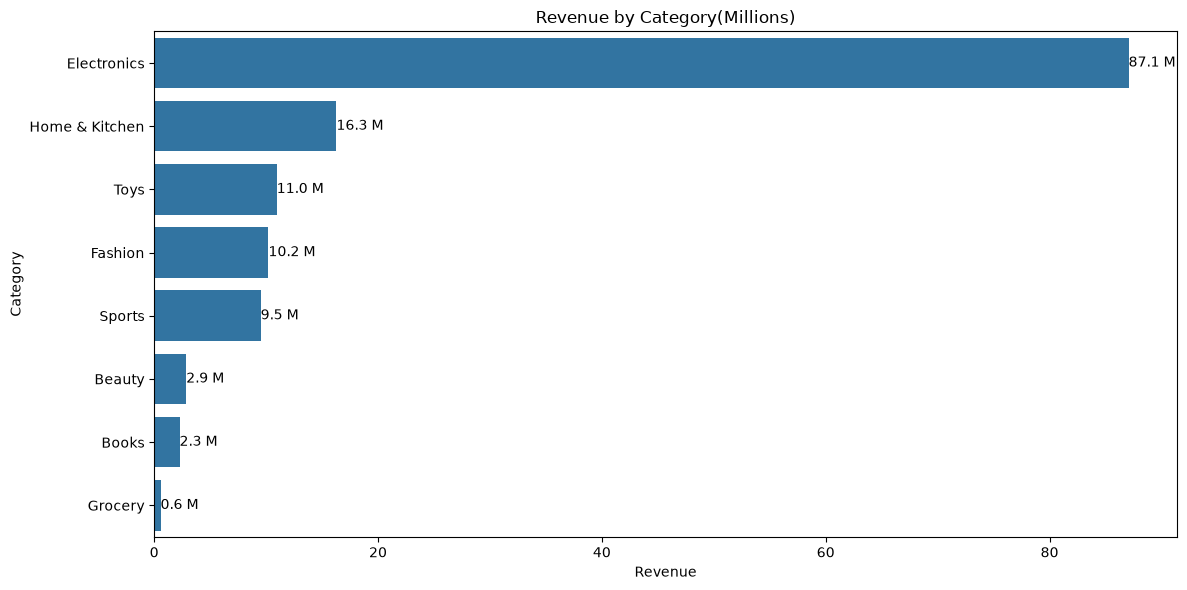

In [70]:
plt.figure(figsize=(12,6))
bars = sns.barplot(data = categ, x='Revenue', y = 'Category')
bars.bar_label(bars.containers[0], fmt = '%.1f M')
plt.title('Revenue by Category(Millions)')
plt.xlabel('Revenue')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

Electronics earns the most money by far, 87 million. That is more than 6 times than the next category.

### Revenue vs profit

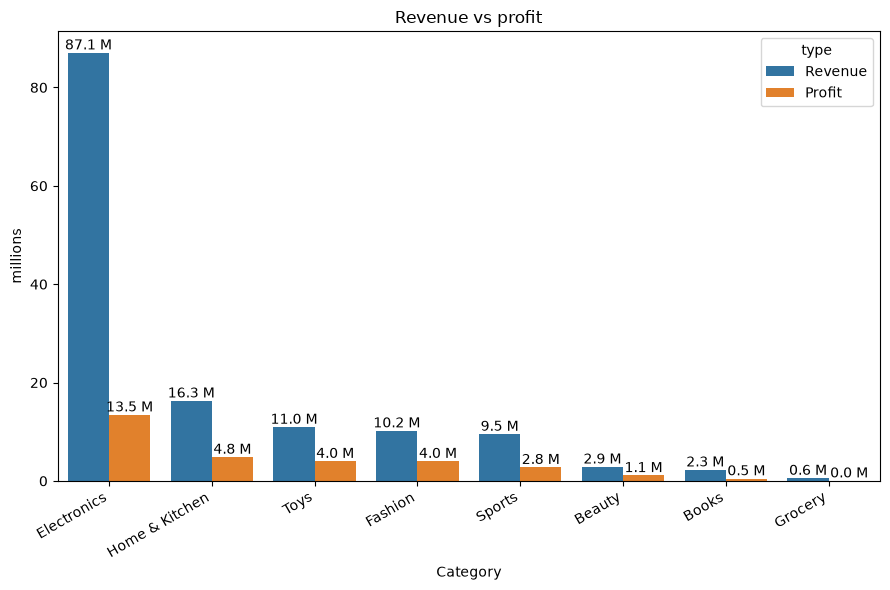

In [85]:
both = categ.melt(id_vars='Category', value_vars=['Revenue', 'Profit'],
                var_name='type', value_name='millions')

plt.figure(figsize=(9, 6))
bar = sns.barplot(data=both, x='Category', y='millions', hue='type')
bar.bar_label(bar.containers[0], fmt = '%.1f M')
bar.bar_label(bar.containers[1], fmt = '%.1f M')
plt.xticks(rotation=30, ha='right')
plt.title('Revenue vs profit')
plt.tight_layout(); plt.show()

Electronics also earns the most profit, but its profit bar is small compared with its revenue bar. It sells a lot, but keeps little.

### Profit margin by category

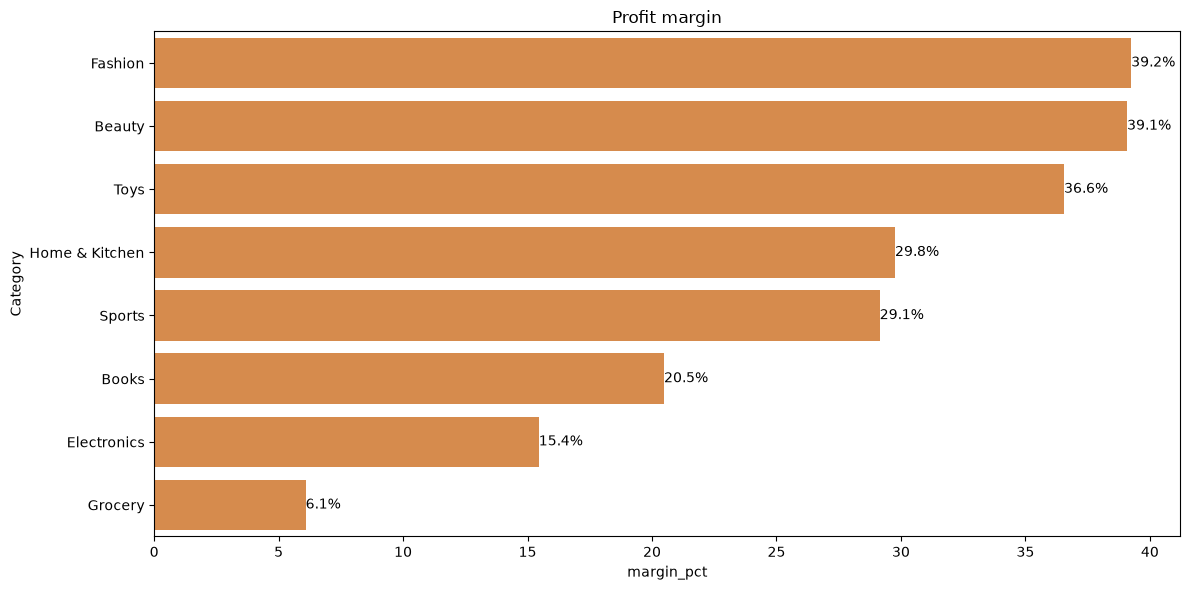

In [89]:
best = categ.sort_values('margin_pct', ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=best, x='margin_pct', y='Category', color='#ed8936')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Profit margin')
plt.tight_layout(); plt.show()

Beauty, Fashion and Toys keep about 36–39 rupees of profit from every 100 of sales. Electronics keeps only 15.4, and Grocery only 6.

### Share of revenue vs share of profit

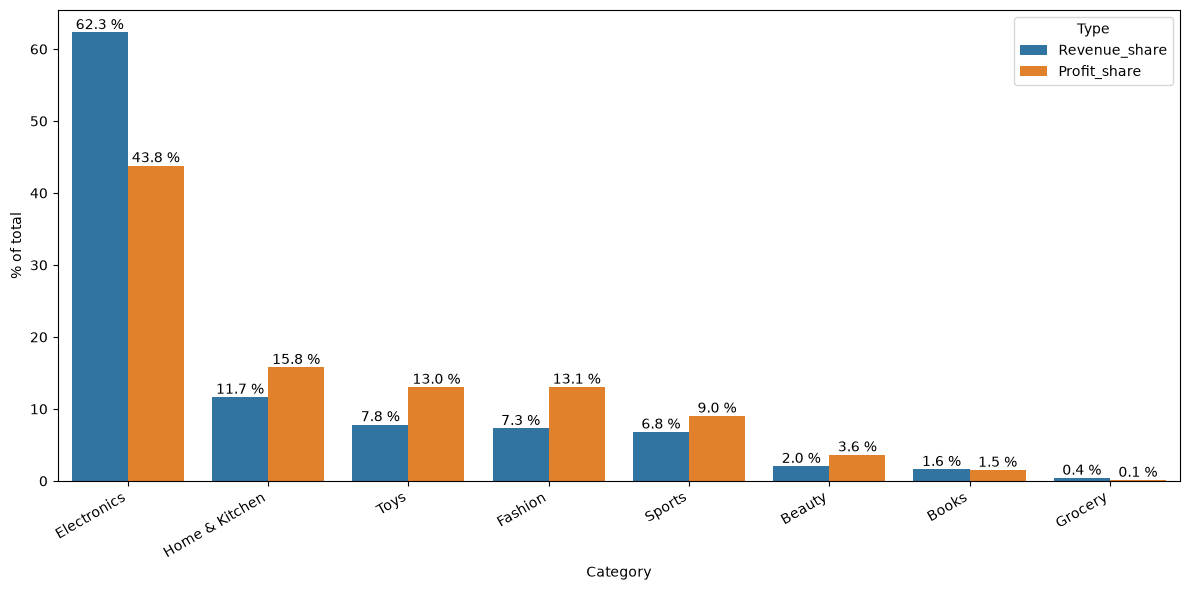

In [97]:
long = share.reset_index().melt(id_vars='Category', var_name='Type', value_name='Percent')

plt.figure(figsize=(12, 6))
Rp = sns.barplot(data=long, x='Category', y='Percent', hue='Type')
Rp.bar_label(Rp.containers[0], fmt = '%.1f %%')
Rp.bar_label(Rp.containers[1], fmt = '%.1f %%')
plt.ylabel('% of total')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Electronics gives 62.3% of the revenue but only 43.8% of the profit. Fashion, Toys and Home & Kitchen & Beauty give more share of profit than of revenue, so they are the efficient ones.

### Conclusion: Revenue is not the same as margin. Electronics is the biggest category, but it is not the most profitable one for each sale. Fashion, Beauty and Toys make the most profit per sale.

    . Reduce dependence on Electronics
    . Promote high-margin categories
    . Cut unprofitable Electronics discounts
    . Fix or drop Grocery
    . Track category mix monthly